In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D
from tensorflow.keras.layers import Flatten, Dense

In [2]:
(x_train, y_train), (x_test, y_test) = mnist.load_data()

print("Training data shape:", x_train.shape)
print("Testing data shape:", x_test.shape)

Training data shape: (60000, 28, 28)
Testing data shape: (10000, 28, 28)


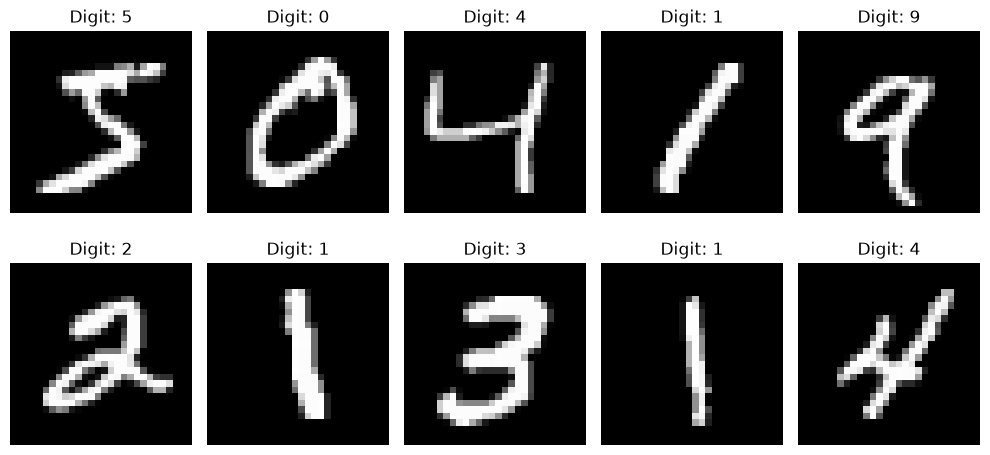

In [3]:
plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title("Digit: " + str(y_train[i]))
    plt.axis('off')

plt.tight_layout()
plt.show()

In [4]:
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

x_train = x_train.reshape(-1, 28, 28, 1)
x_test = x_test.reshape(-1, 28, 28, 1)

print("Training shape:", x_train.shape)
print("Testing shape:", x_test.shape)

Training shape: (60000, 28, 28, 1)
Testing shape: (10000, 28, 28, 1)


In [5]:
model = tf.keras.Sequential([

    tf.keras.layers.Input(shape=(28, 28, 1)),

    # First Convolutional Layer
    tf.keras.layers.Conv2D(
        32, (3, 3), activation='relu'
    ),

    # First Max Pooling Layer
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Second Convolutional Layer
    tf.keras.layers.Conv2D(
        64, (3, 3), activation='relu'
    ),

    # Second Max Pooling Layer
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Flatten Layer
    tf.keras.layers.Flatten(),

    # Fully Connected Layer
    tf.keras.layers.Dense(128, activation='relu'),

    # Output Layer
    tf.keras.layers.Dense(10, activation='softmax')
])

In [6]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [7]:
history = model.fit(
    x_train,
    y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.2
)

Epoch 1/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 12s 14ms/step - accuracy: 0.9448 - loss: 0.1844 - val_accuracy: 0.9757 - val_loss: 0.0824
Epoch 2/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 11s 14ms/step - accuracy: 0.9833 - loss: 0.0538 - val_accuracy: 0.9851 - val_loss: 0.0518
Epoch 3/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 11s 14ms/step - accuracy: 0.9877 - loss: 0.0388 - val_accuracy: 0.9897 - val_loss: 0.0377
Epoch 4/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 11s 14ms/step - accuracy: 0.9910 - loss: 0.0280 - val_accuracy: 0.9841 - val_loss: 0.0486
Epoch 5/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 11s 14ms/step - accuracy: 0.9935 - loss: 0.0211 - val_accuracy: 0.9893 - val_loss: 0.0388


In [8]:
test_loss, test_accuracy = model.evaluate(x_test, y_test)

print("Test Loss:", test_loss)
print("Testing Accuracy:", test_accuracy * 100, "%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9919 - loss: 0.0254
Test Loss: 0.02541889250278473
Testing Accuracy: 99.19000267982483 %


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step


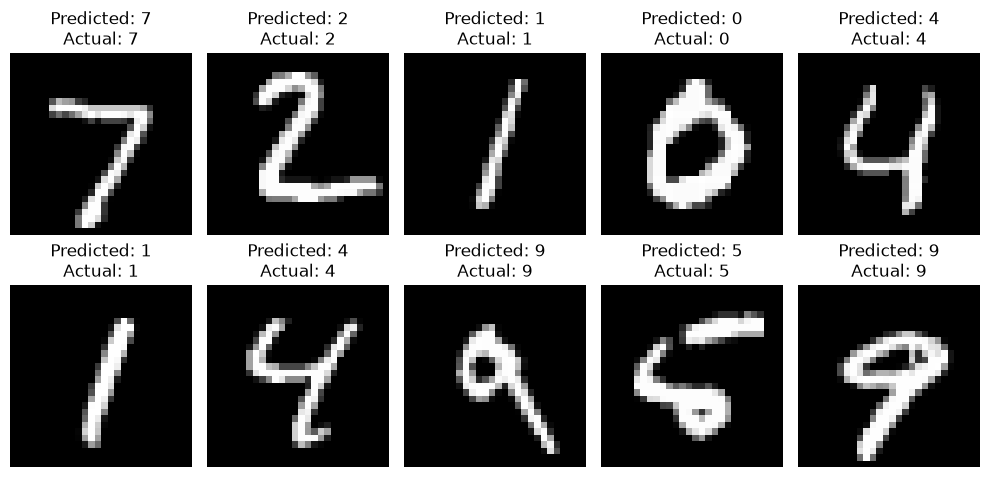

In [9]:
predictions = model.predict(x_test[:10])

predicted_labels = np.argmax(predictions, axis=1)

plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[i].reshape(28, 28), cmap='gray')

    plt.title(
        f"Predicted: {predicted_labels[i]}\nActual: {y_test[i]}"
    )

    plt.axis('off')

plt.tight_layout()
plt.show()

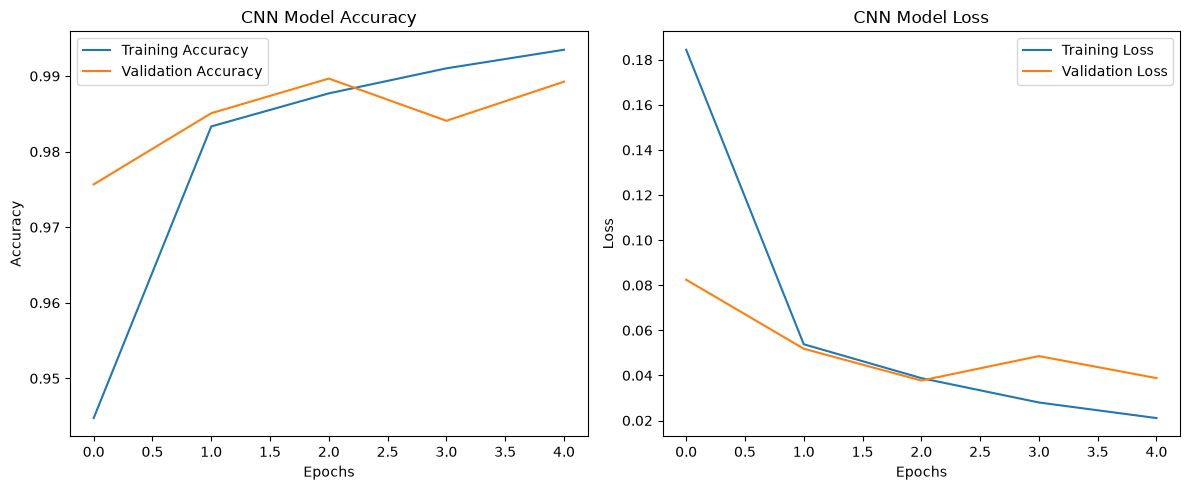

In [10]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('CNN Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('CNN Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
# Develop a CNN model using TensorFlow/Keras to recognize handwritten
# digits. Apply convolution and max-pooling operations, train the model
# and display testing accuracy.
# Use Dataset - Handwritten MNIST